## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

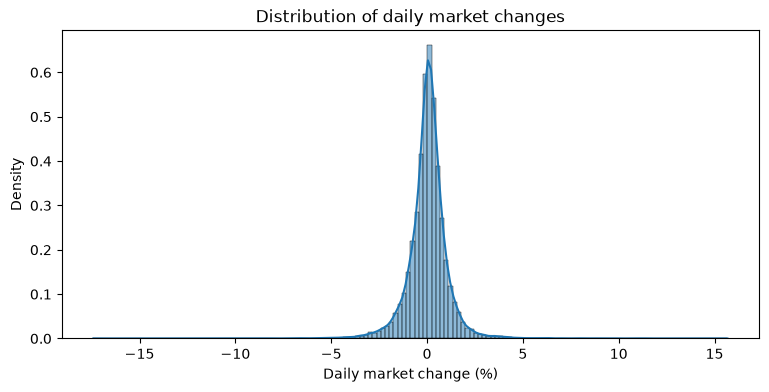

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

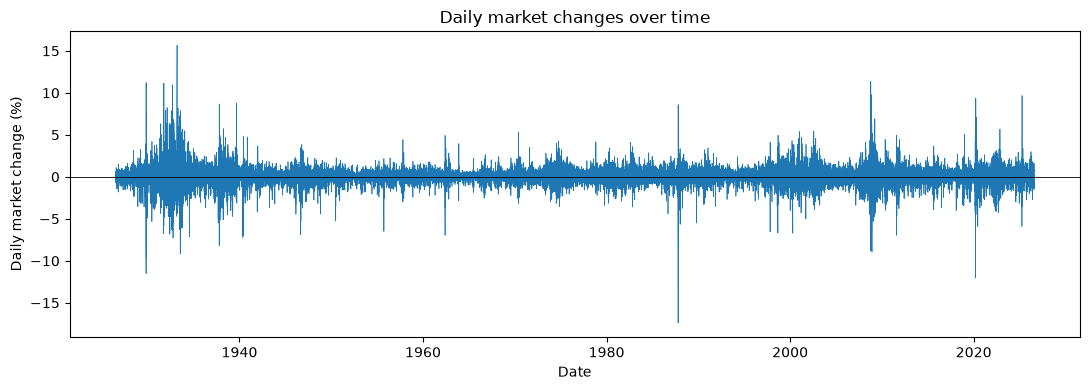

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [ ]:
# bullet 1
#display(df['market_return_pct'])

# making a new variable bins to capture whether returns are up & down/flat similar to review cond notebook
df['bin'] = df['market_return_pct'] > 0 # uses a simple if true to get the 1
df['y_t'] = df['bin'].map({False: 'Down', True: 'Up'}) 

# making a new variable to capture the returns from the previous day similar to the review cond notebook using shift(-1) and updating dictionary map
df['y_tp1'] = df['bin'].shift(-1).map({False: 'Down', True: 'Up'})

# looking at the crosstab table
pd.crosstab(df['y_t'], df['y_tp1'])

y_tp1,Down,Up
y_t,,
Down,5909,5999
Up,5999,8388


y_tp1,Down,Up,All
y_t,,,
Down,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


<Axes: xlabel='y_tp1', ylabel='y_t'>

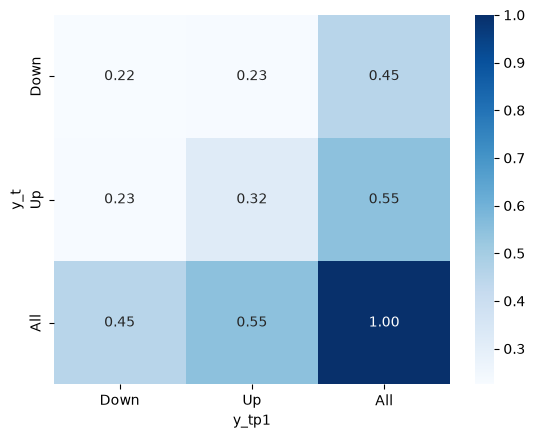

In [ ]:
# bullet 2 (joint PMF with marginals)

# again adapting the code from the notebook to get the joint pmf and marginals, we only need the code for marginals since it just adds to the joint PMF
# adding margins = True so we can see the totals for up/down for each day and the totals for the up/down for each day depending on the previous day
tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize = True, margins = True)
display(tab)

# creating the heatmap
sns.heatmap(tab, annot=True, fmt='.2f', cmap='Blues')

y_tp1,Down,Up
y_t,,
Down,0.496221,0.503779
Up,0.416974,0.583026


<Axes: xlabel='y_tp1', ylabel='y_t'>

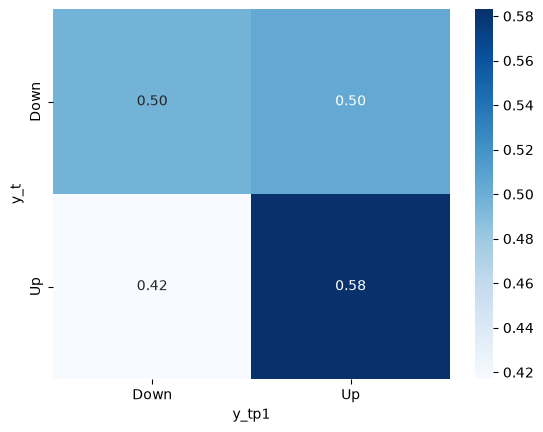

In [ ]:
# bullet 2 (conditional PMF)
tab = pd.crosstab(df['y_t'], df['y_tp1'],
            normalize = 'index')
display(tab)
sns.heatmap(tab, annot=True, fmt='.2f', cmap='Blues')

#### Are up transitions more or less common than down transitions? 

> Based on the output of the heatmap or crosstab from the joint PMF with the marginals, we can read the rightmost column to look at the total proportions of up/down days. We see that down has a value of 0.45, meaning that 45% of the days were down/flat. The value for up is 0.55, meaning that 55% of the days were up. Comparing these proportions, we can see that it is more common to have an up day by 10 percentage points. Now looking at the heatmap for the conditional PMF, we can see that if y_t is down, there is a 50% chance of going down again and a 50% change of going up. If we have an up day, we have a 42% chance of going down and 0.58% change of going up. Because, we have more up days that are more likely to stay up and fewer down days that evenly split into up/down days, we know that it is more common to have an up transition. The math below helps shows this:

Up transitions: 
- Case 1: up-up $\rightarrow (0.55) \cdot (0.58) = 0.319$
- Case 2: down-up $\rightarrow (0.45) \cdot (0.5) = 0.225$
- Total: $ (0.319 + 0.225) = 0.544 $

Down transitions: 
- Case 1: up-down $\rightarrow (0.55) \cdot (0.42) = 0.231$
- Case 2: down-down $\rightarrow (0.45) \cdot (0.5) = 0.225$
- Total: $ (0.231 + 0.225) = 0.456 $

Comparing: 
- Up transitions (0.5440) > Down transitions (0.456)
 
#### Are you more likely to transition to an Up day from a Down or Up day?

> Based on the conditional PMF heatmap, P(Up tomorrow | Up today) = 0.58 and P(Up tomorrow | Down today) = 0.5. Comparing these two value, we can see that it is more likely to go to an up day when coming from an up day by about 8 percentage points.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [ ]:
# bullet 1
# adapting the code from the notbook
df['ret_bin'] = pd.cut(
    df['market_return_pct'],
    bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf],
    labels=['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
)
df['y_t'] = df['ret_bin']
df['y_tp1'] = df['ret_bin'].shift(-1)

# counting the values in each bin
print(df['y_t'].value_counts())
# normalizing to get the percentages for each bin
print(df['y_t'].value_counts(normalize=True))

y_t
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64
y_t
Small gain    0.372110
Small loss    0.283389
Near zero     0.130856
Large gain    0.108724
Large loss    0.104921
Name: proportion, dtype: float64


y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


[Text(0.5, 1.0, 'Joint PMF')]

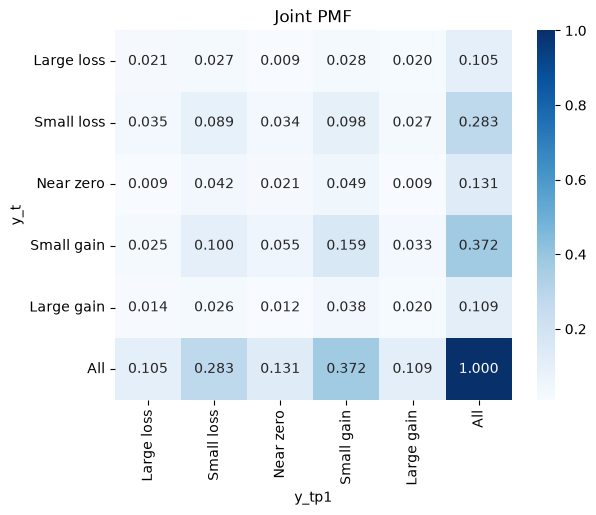

In [ ]:
# bullet 2
# computing the joint pmf with marginals
# joint pmf with marginals
tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True, margins=True)
display(tab)
# heatmap
sns.heatmap(tab, annot=True, fmt='.3f', cmap='Blues').set(title='Joint PMF')

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


[Text(0.5, 1.0, 'Conditional PMF')]

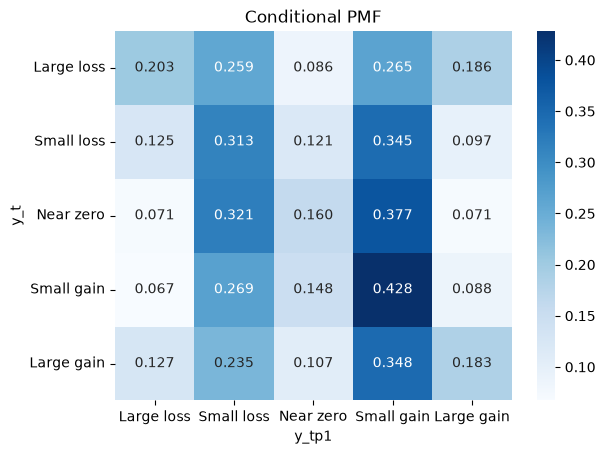

In [23]:
# bullet 3
# computing the conditional pmf
tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
display(tab)
# heatmap of the conditional
sns.heatmap(tab, annot=True, fmt='.3f', cmap='Blues').set(title='Conditional PMF')

In [ ]:
# bullet 4
# computing the conditional expectation
df['ret_tp1'] = df['market_return_pct'].shift(-1)
df.groupby('y_t', observed=False)['ret_tp1'].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


#### How many days fall into each of the five bins? Which are the most or least common?

> The value counts for each of the bins is shown above. The most common bin is small gain, which occurs 9785 times in the data or 37.2% of the time. The next most common bin is small loss, which occurs 7452 times to be 28.3% of the time. The rest of the bins are near zero 3441 times or 13.1% of the time, large gain 2859 or 10.9% of the time, and lastly large loss 2759 times or 10.5% of the time. So, small gain is the most common and large loss is the least common.


#### Which transitions are most likely to occur?

> By looking at the values not including the rightmost or bottommost (marginals), we can find the most likely transitions. The largest value is 0.159 for small gain to small gain, so there is a 15.9% chance that we go from small gain to small gain. The next largest value is 0.1 for small gain to small loss, so there is a 10% chance that we go from a small gain to a small loss. The third most likely transition is from small loss to small loss that occurs 8.9% of the time. These percentages capture the chance of each transition without conditioning on the returns for any of the days (ie going from small gain to a small gain after knowing that we are currently sitting at a small gain is different). Also, all of these most popular transitions are between the small bins which makes sense because the small bins capture almost 80% of the data.


#### For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?

> For all of the states here are the two most likely future states with their percentages:

| Today's state | Most likely next state | 2nd most likely next state |
| --- | --- | --- |
| Large loss | Small gain (26.5%) | Small loss (25.9%) |
| Small loss | Small gain (34.5%) | Small loss (31.3%) |
| Near zero | Small gain (37.7%) | Small loss (32.1%) |
| Small gain | Small gain (42.8%) | Small loss (26.9%) |
| Large gain | Small gain (34.8%) | Small loss (23.5%) |

> Again, we can see that the two most common transitions are always to small bins because the small bins make up so much of our data. Now looking at how close each row is to uniform, a uniform row would have 0.2 or 20% for each column. Across the table, values hover between around 0.07-0.43. Going row by row, the large loss row appears to be the most uniform since the values are closest to 0.2. For the rest of the rows, the values are not uniform at all, which there being very low values for large loss and generally high values for small loss or small gain, again reflecting that these are the two most popular bins by far. So, the rows are not very uniform. Given that the rows are generally not uniform, we should be able to use these conditional values to better predict the outcome for the next day than randomly guessing (uniform values would indicate that conditioning is the same as randomly guessing). While it will still not be easy to predict the next state, the large values around small gain and small loss mean that we should do a relatively good job of predicting the next state if we pick either of these values, though no value is ever above 0.5 so we should never have more than 50% confidence in correctly predicting the next state. The most confident prediction we can make is predicting a small gain given that the previous day is a small gain, correct 42.8% of the time.


#### Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice.

> Looking at the last table with the conditional expectations, we can find the expected percent return for tomorrow given each state. When there is a large loss, we expect a return of -0.04% the next day. When there is a large gain, we expect a return of 0.16% the next day. If we have a small loss, the expected next return is -0.04% and if we have a small gain the expected next return is 0.11%. Lastly, if we have near zero, the next expected return is 0.02%. All of these expected returns are relatively small and check with most of our data falling into small gain or small loss. The min and max values are most extreme for the large gains (-12$ to 15.7%) and large loss (-17.4% to 11.2%). The states with the highest standard deviation are large loss (1.72) and large gain (1.38). These results makes sense because we expect the most volatile days to follow volatile days. We also see that near zero has the lowest standard deviation and the shortest range between min and max returns, meaning that we expect the least volatility after low volatile days. So, we can see that the volatility of the next day is somewhat predictable based on the volatility of today.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [ ]:
# bullet 1
# assigning values to the 21 bins

df['y_t'] = pd.qcut(df['market_return_pct'], q=21, labels=False) # looked up how to use qcut and plugged in the correct parameters
df['y_tp1'] = df['y_t'].shift(-1)

# looking at the values in each bin
df['y_t'].value_counts().sort_index()
# these look pretty uniformly distributed which makes sense because we used quantiles to help avoid the large class imbalances like before

y_t
0     1255
1     1253
2     1286
3     1280
4     1230
5     1226
6     1371
7     1206
8     1198
9     1331
10    1210
11    1223
12    1294
13    1223
14    1310
15    1193
16    1211
17    1283
18    1225
19    1250
20    1238
Name: count, dtype: int64

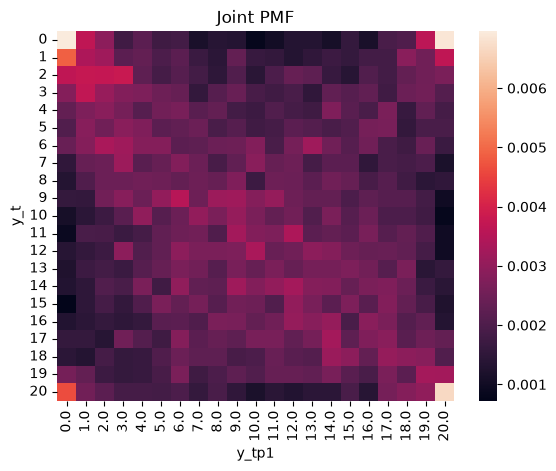

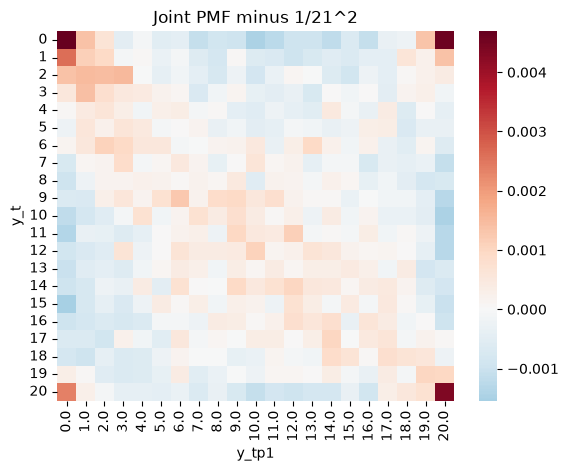

In [ ]:
# bullet 2
# computing the joint PMF and plotting its heat map
tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
sns.heatmap(tab).set(title='Joint PMF')
plt.show()

# now subtracting 1/21**2 to look at the differences
sns.heatmap(tab - 1/21**2, cmap='RdBu_r', center=0).set(title='Joint PMF minus 1/21^2')
plt.show()

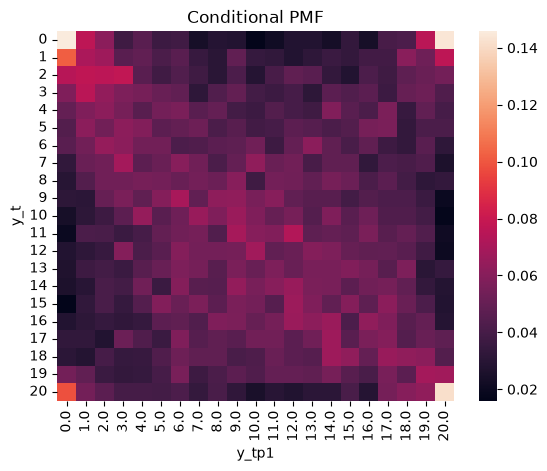

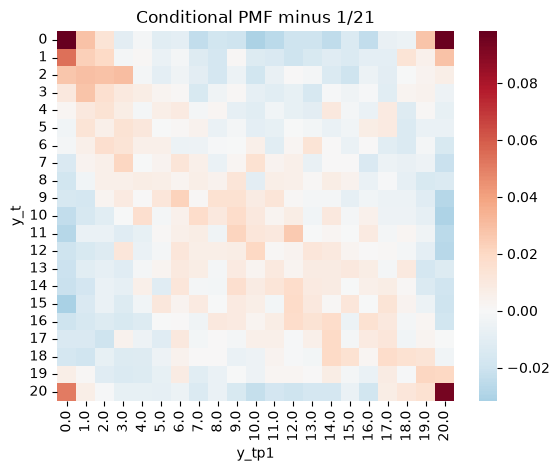

In [29]:
# bullet 3
# computing the conditional PMF and its heat map

# Adapted from review_conditioning.ipynb, cells bd7f55c7 and daa9efd9
tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
sns.heatmap(tab).set(title='Conditional PMF')
plt.show()

# now subtracting 1/21
sns.heatmap(tab - 1/21, cmap='RdBu_r', center=0).set(title='Conditional PMF minus 1/21')
plt.show()

<Axes: title={'center': 'Next-day min, mean, max by bin'}, xlabel='y_t'>

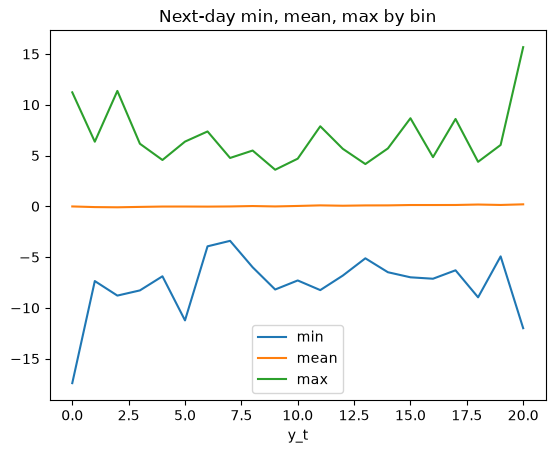

In [ ]:
# bullet 4
# computing the next days min/mean/max and plotting

df['ret_tp1'] = df['market_return_pct'].shift(-1) # getting returns for the next day
# grouping by the returns of the next day and computing the stata
# using .plot to plot this directly (found online)
df.groupby('y_t')['ret_tp1'].agg(['min', 'mean', 'max']).plot(title='Next-day min, mean, max by bin')

<Axes: title={'center': 'Next-day std by bin'}, xlabel='y_t'>

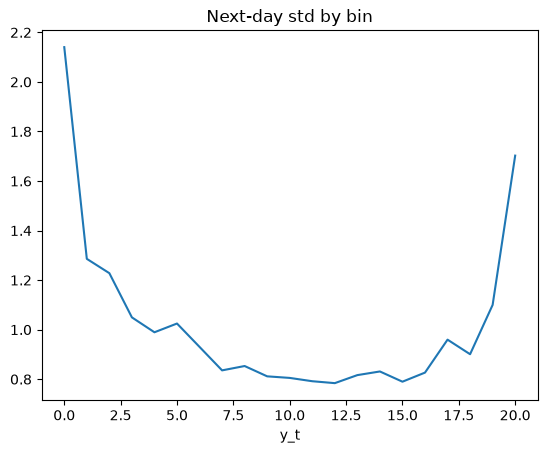

In [36]:
# bullet 5
# plotting the std for the next day by using .std() to get the std of returns
df.groupby('y_t')['ret_tp1'].std().plot(title='Next-day std by bin')

#### Do you see any obvious patterns (in regards to the joint PMF)? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.

> The first joint PMF heatmap looks pretty uninformative because all of the values hover around the same values so they get a deep red color. That said, we can see slightly lighter hues on the diagonals and at the corners of the graph. The corners having larger values means that the extremes are more likely to connect to other extremes which we know in the case from before. After subtracting 1/21^2 this pattern becomes a little more clear because now values hover around 0 so the change between positive and negative values is easy to see. We again see the diagonals having slightly larger values with the largest being in the corners. This confirms that extreme days are followed by extreme days much more often than uniform/random. The positive values along the diagonals indicate that days tend to be followed by days of a similar size, which again matches what we found before. The largest deviations from the uniform values occur at these corners/values since we know that the probability of having the next day was similar to the current day has a higher probability than randomly picking a day (so this heat map can help us beat random guess/uniform values).


#### Do you see any obvious patterns (in regards to the conditional PMF)? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.

> The heatmap of the conditional PMF before and after subtracting 1/21 show the same patterns captured by the joint PMF. After subtracting 1/21 the four corners stand out the most with positive values and the diagonals capture the next highest values. This leads us to the same conclusion: given that today is really bad (good), the chance that tomorrow is also in really bad (good) is much larger than all of other chances. In those same extreme cases, the values of going to another extreme case are high while the values for the less extreme bins around 2-18 are less common and have values below the uniform value. Furthermore, calmer days are followed by calm days and volatile days are followed by volatile days, as we can see from the larger values on the diagonal capturing the percentages from one bin to itself the next day. That said, since there are many bins and all the values are pretty low, it is still very hard to predict the exact bin of the following day knowing what today is, but we have agood chance at predicting a range of bins and the volatility of that bin.


#### Do you see any obvious patterns (in regards to the next day's min/mean/max)? Explain. 

> In this plot we have 3 different lines to capture the min, mean, and max. The most obvious result of this is that the mean line lies pretty much flat at 0 for all of the bins. This tells us that no matter what bin we are in today, the expected value/mean return for the next day is 0. This means that taking the conditional expected value for the next days return based on todays return shouldn't beat the market alone. Another pattern that emerges is the general symmetry between the min and max line, where they move in almost opposite directions. This captures the trend that expected returns for the next day are pretty much symmetrical and centered around 0, but this spread is dependent on how extreme the bin is. The min/max lines appear to get more extreme the further away they get from the middle, even more evidence that calmer days lead to less volatile returns the next day and more extreme days lead to more volatile returns the next day. 


#### Do you see any obvious patterns (in regard to the next day's standard deviation)? Explain.

> This standard deviation plot is clearly U-shaped, which matches our conclusions from before. It is highest at bins 0-2 and bins 19-20. Bin 0 has a large std of about 2.2 which then drops to around 0.8 at bin 11, before rising to around 1.6 at bin 20. The sharp dip, steady down/up, and sharp rise is the U-shaped pattern that is consistent with our findings that more volatile days are followed by more volatile days. This high correlation between volatility means we should have decent information about tomorrows volatility given what is today (although this volatility does not capture positive/negative returns). Lastly, the left side is higher than the right so big losses are followed by more uncertainty than big gains. 


#### How easy is it to predict the market?

> Putting all of this together, the market is not easy to predict. The conditional expected returns are very close to zero, and they are tiny compared to the large standard deviations (around 0.8% to 2.1%). We have also seen that we are much better at predicting the volatilty of the next day given todays volatility, but we are not sure which direction this volatility will push the sign of the returns towards. The strongest cell in the conditional PMF, from bin 0 to bin 0, only happens about 1/8 of the time, but from the extreme bins the next day is almost equally likely to land in either extreme so we could do really good or really bad. All together, the market's direction is close to unpredictable from today's bin alone while the size of the next move (volatility) is somewhat predictable, meaning that we have very little useful information to beat the market.